# 🧠 Pipeline d'Analyse Comportementale via Computer Vision (DeepLabCut)

**Objectif du projet :**
Ce notebook illustre le traitement post-extraction d'un modèle d'intelligence artificielle (DeepLabCut). À partir de données de tracking brutes (séries temporelles de coordonnées X, Y), l'objectif est d'extraire des métriques actionnables, d'appliquer des filtres de vraisemblance et de modéliser des états comportementaux complexes.

**Stack Technique :** `Python`, `Pandas` (Time-series), `NumPy` (Algèbre linéaire), `Seaborn/Matplotlib` (DataViz).

In [1]:
# ==============================================================================
# 1. IMPORTS & CONFIGURATION GLOBALE
# ==============================================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration esthétique pour des graphiques de qualité "présentation"
sns.set_theme(style="ticks", context="notebook", font_scale=1.2)
plt.rcParams["figure.figsize"] = (10, 6)

# ==============================================================================
# 2. GESTION ROBUSTE DES CHEMINS (PATHS)
# ==============================================================================
# Path.cwd() garantit que le code fonctionne sur n'importe quel OS (Windows, Mac, Linux)
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"

# Remplace ceci par le nom exact de ton fichier d'exemple présent dans le dossier 'data'
FILE_NAME = "enregistrement_cam1_20260428_132249_5_GreyscaleDLC_DekrW32_Heroin-M1Jun3shuffle7_snapshot_best-500.csv"
FILE_PATH = DATA_DIR / FILE_NAME

# ==============================================================================
# 3. CHARGEMENT UNIQUE DES DONNÉES
# ==============================================================================
if not FILE_PATH.exists():
    raise FileNotFoundError(f"⚠️ Fichier introuvable : {FILE_PATH}. Placez le fichier dans le dossier 'data/'.")

# Lecture du CSV généré par DeepLabCut (gestion du MultiIndex propre à DLC)
df = pd.read_csv(FILE_PATH, header=[0, 1, 2], index_col=0)

# Extraction dynamique du nom du Scorer (le réseau de neurones)
scorer = df.columns.levels[0][0]

print(f"✅ Données chargées avec succès.")
print(f"📊 Dimensions du dataset : {df.shape[0]} frames analysées.")

✅ Données chargées avec succès.
📊 Dimensions du dataset : 323984 frames analysées.


## 1. Filtrage et Nettoyage des Données (Data Preprocessing)
Les modèles de Computer Vision génèrent parfois des artefacts visuels. La première étape consiste à appliquer un filtre de confiance strict : nous ne conservons que les coordonnées où le réseau de neurones a une certitude supérieure à 90% (`likelihood > 0.90`).

In [2]:
# Définition du seuil de confiance métier
SEUIL_CONFIANCE = 0

# Création d'un masque de filtre sur une partie centrale du corps (ex: dorsal_2)
# Remplacer 'dorsal_2' par le point de référence central de ton modèle si différent
masque_confiance = df[scorer]['dorsal_2']['likelihood'] > SEUIL_CONFIANCE

# Application du filtre : on remplace les coordonnées aberrantes par du vide (NaN)
# Cela permet d'éviter de fausser les calculs mathématiques futurs
df_clean = df.copy()
df_clean.loc[~masque_confiance, (scorer, 'dorsal_2', 'x')] = np.nan
df_clean.loc[~masque_confiance, (scorer, 'dorsal_2', 'y')] = np.nan

print(f"🧹 Filtrage terminé : {sum(~masque_confiance)} frames considérées comme du bruit ont été isolées.")

🧹 Filtrage terminé : 5356 frames considérées comme du bruit ont été isolées.


## 2. Analyse Cinématique et Classification d'États
À partir des coordonnées lissées du centre de gravité, nous calculons la dérivée spatiale pour obtenir la vitesse de déplacement (en pixels/frame). 

**Application d'une règle métier (Business Logic) :**
En appliquant une moyenne mobile (`rolling mean`) pour absorber le micro-bruit temporel, nous définissons un seuil permettant de classifier automatiquement l'état du sujet : **En mouvement** vs **Immobile**.

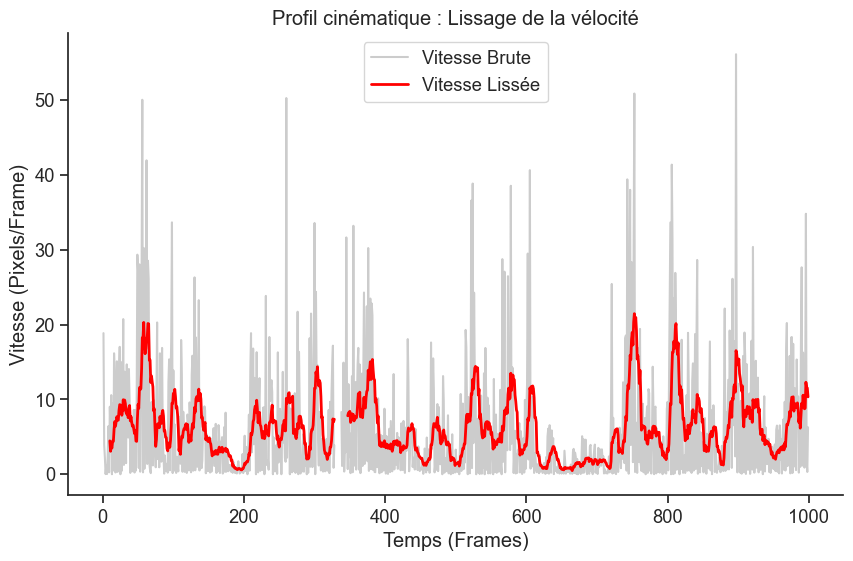

In [3]:
# 1. Calculs des vecteurs (Séries simples)
# On extrait les données directement sans modifier la structure de df_clean
x = df_clean[scorer]['dorsal_2']['x']
y = df_clean[scorer]['dorsal_2']['y']

# 2. Calculs cinématiques
dx = x.diff()
dy = y.diff()
vitesse_brute = np.sqrt(dx**2 + dy**2)

# 3. Moyenne mobile (Lissage)
vitesse_lissee = vitesse_brute.rolling(window=10).mean()

# 4. Création d'un DataFrame de métriques dédié (C'est la méthode pro)
# On ne touche plus au df_clean (le MultiIndex) pour éviter les erreurs de structure
metrics_df = pd.DataFrame({
    'Vitesse_Brute': vitesse_brute,
    'Vitesse_Lissée': vitesse_lissee
})

# 5. Tracé du graphique
plt.figure(figsize=(10, 6))
# On trace les données du DataFrame de métriques que nous venons de créer
plt.plot(metrics_df['Vitesse_Brute'][:1000], label='Vitesse Brute', alpha=0.4, color='gray')
plt.plot(metrics_df['Vitesse_Lissée'][:1000], label='Vitesse Lissée', color='red', linewidth=2)

plt.title("Profil cinématique : Lissage de la vélocité")
plt.xlabel("Temps (Frames)")
plt.ylabel("Vitesse (Pixels/Frame)")
plt.legend()
sns.despine()
plt.show()

## 3. Feature Engineering : Extraction de variables morphologiques
Pour comprendre la posture, nous créons une nouvelle variable : la distance euclidienne entre le museau (`nose`) et la base de la queue (`tail_base`). L'analyse de la distribution de cette longueur permet d'identifier des motifs comportementaux (étirement d'exploration vs recroquevillement).

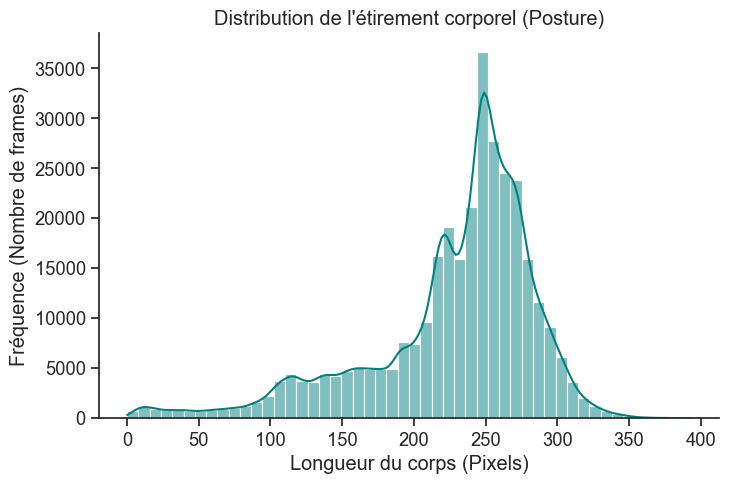

In [4]:
# 1. Extraction des coordonnées (Séries simples)
x_nose = df_clean[scorer]['nose']['x']
y_nose = df_clean[scorer]['nose']['y']
x_tail = df_clean[scorer]['tail_base']['x']
y_tail = df_clean[scorer]['tail_base']['y']

# 2. Calcul de la métrique en série simple
longueur_corps = np.sqrt((x_nose - x_tail)**2 + (y_nose - y_tail)**2)

# 3. Création d'un DataFrame temporaire pour le tracé (Propre et robuste)
metrics_df = pd.DataFrame({
    'Longueur_Corps': longueur_corps
})

# 4. Visualisation (on utilise metrics_df au lieu de df_clean)
plt.figure(figsize=(8, 5))
sns.histplot(metrics_df['Longueur_Corps'].dropna(), bins=50, kde=True, color="teal")

plt.title("Distribution de l'étirement corporel (Posture)")
plt.xlabel("Longueur du corps (Pixels)")
plt.ylabel("Fréquence (Nombre de frames)")
sns.despine()
plt.show()

## 4. Modélisation de l'Occupation Spatiale (Heatmap)
Les coordonnées continues sont discrétisées dans une grille bidimensionnelle (Matrice via `histogram2d`). Cette agrégation génère une "Heatmap" mettant en évidence les Zones d'Intérêt (ROI - Regions of Interest) privilégiées lors de la recherche de récompense.

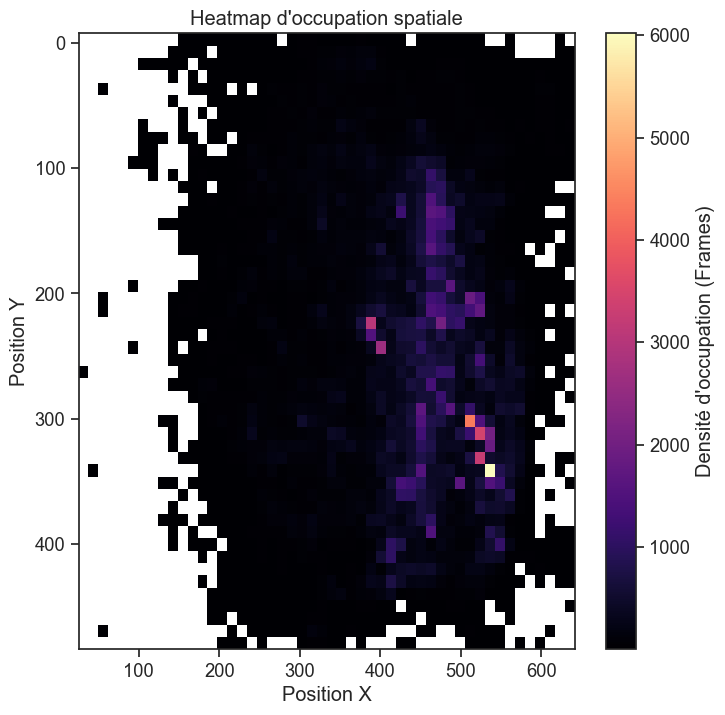

In [5]:
# Récupération des coordonnées X et Y sans les NaN
x_coords = df_clean[scorer]['dorsal_2']['x'].dropna()
y_coords = df_clean[scorer]['dorsal_2']['y'].dropna()

# Création d'une Heatmap d'occupation spatiale
plt.figure(figsize=(8, 8))
# On inverse l'axe Y pour correspondre à la vue de la caméra (origine en haut à gauche)
plt.hist2d(x_coords, y_coords, bins=50, cmap='magma', cmin=1)
plt.colorbar(label="Densité d'occupation (Frames)")
plt.gca().invert_yaxis() 
plt.title("Heatmap d'occupation spatiale")
plt.xlabel("Position X")
plt.ylabel("Position Y")
plt.show()

## 5. Analyse Vectorielle : Direction de la tête et projection du regard
Étape analytique avancée utilisant l'algèbre linéaire pour reconstituer un vecteur directionnel représentant l'orientation de la tête :
1. Calcul du point central entre les deux oreilles.
2. Création d'un vecteur reliant ce centre au nez.
3. Calcul de l'angle en radians (`np.arctan2`) et conversion en degrés.

Ce traitement permet de catégoriser dynamiquement la cible de l'attention visuelle sans intervention humaine.

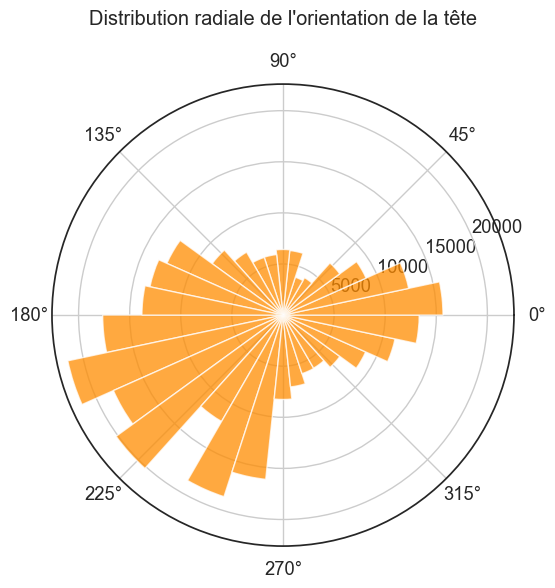

In [6]:
# 1. Calcul du centre géométrique entre les deux oreilles
ear_mid_x = (df_clean[scorer]['ear_left']['x'] + df_clean[scorer]['ear_right']['x']) / 2
ear_mid_y = (df_clean[scorer]['ear_left']['y'] + df_clean[scorer]['ear_right']['y']) / 2

# 2. Vecteur directionnel : du milieu des oreilles vers le museau
vecteur_x = x_nose - ear_mid_x
vecteur_y = y_nose - ear_mid_y

# 3. Calcul de l'angle d'orientation (en radians, puis degrés)
angle_rad = np.arctan2(vecteur_y, vecteur_x)
angle_deg = np.degrees(angle_rad)

# --- FIN DU CALCUL ---
# On ne touche plus à df_clean ici, c'est ce qui faisait planter ton code.

# 4. Visualisation polaire de la direction du regard
plt.figure(figsize=(6, 6))
ax = plt.subplot(111, projection='polar')

# On utilise angle_rad directement pour le tracé polaire
# Nettoyage des NaN pour éviter que Matplotlib ne plante
angles_valides = angle_rad.dropna()

# Tracé
ax.hist(angles_valides, bins=30, color='darkorange', alpha=0.75)
ax.set_title("Distribution radiale de l'orientation de la tête", pad=20)
plt.show()